In [13]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay,
)

print(" Libraries imported successfully!")

Mounted at /content/drive
✅ Libraries imported successfully!


In [14]:
DRIVE_PATH = '/content/drive/MyDrive/cleaned_email_dataset.csv'

df = pd.read_csv(DRIVE_PATH)

# Safety checks
df = df.dropna(subset=['final_nlp_text', 'risk_label'])
df = df[df['final_nlp_text'].str.strip() != '']
df['risk_label'] = df['risk_label'].astype(int)

label_names = {
    0: 'Ham (Low Risk)',
    1: 'Spam (Mid Risk)',
    2: 'Phishing (High Risk)'
}

print(f" Dataset loaded: {len(df):,} rows")
print(f"   Columns: {df.columns.tolist()}")
print(f"\nClass distribution:")
for label, name in label_names.items():
    count = (df['risk_label'] == label).sum()
    pct   = count / len(df) * 100
    print(f"  {name:25s} → {count:>6,}  ({pct:.1f}%)")

# Hard check — raises an error immediately if any class is missing
missing = {0, 1, 2} - set(df['risk_label'].unique())
if missing:
    raise ValueError(f" Missing classes: {missing}. Re-check your CSV file.")
else:
    print("\n All 3 classes confirmed present. Safe to proceed.")

✅ Dataset loaded: 131,026 rows
   Columns: ['final_nlp_text', 'risk_label']

Class distribution:
  Ham (Low Risk)            → 42,805  (32.7%)
  Spam (Mid Risk)           → 45,390  (34.6%)
  Phishing (High Risk)      → 42,831  (32.7%)

✅ All 3 classes confirmed present. Safe to proceed.


In [15]:
X = df['final_nlp_text']
y = df['risk_label']

# stratify=y ensures all 3 classes appear proportionally in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Training set : {len(X_train):,} samples")
print(f"Testing set  : {len(X_test):,} samples")
print("\nTraining class distribution:")
for label, name in label_names.items():
    count = (y_train == label).sum()
    print(f"  {name:25s} → {count:>6,}")

Training set : 104,820 samples
Testing set  : 26,206 samples

Training class distribution:
  Ham (Low Risk)            → 34,244
  Spam (Mid Risk)           → 36,312
  Phishing (High Risk)      → 34,264


In [16]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=100_000,
    sublinear_tf=True,
    min_df=2,
    strip_accents='unicode',
    analyzer='word',
)

print("Fitting TF-IDF vectorizer on training data...")
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f" TF-IDF complete.")
print(f"   Training matrix : {X_train_tfidf.shape[0]:,} emails × {X_train_tfidf.shape[1]:,} features")
print(f"   Testing matrix  : {X_test_tfidf.shape[0]:,} emails × {X_test_tfidf.shape[1]:,} features")

# Save vectorizer to Drive immediately
VECTORIZER_PATH = '/content/drive/MyDrive/tfidf_vectorizer.pkl'
joblib.dump(tfidf, VECTORIZER_PATH)
print(f"\n Saved: tfidf_vectorizer.pkl → Google Drive")

Fitting TF-IDF vectorizer on training data...
✅ TF-IDF complete.
   Training matrix : 104,820 emails × 100,000 features
   Testing matrix  : 26,206 emails × 100,000 features

✅ Saved: tfidf_vectorizer.pkl → Google Drive


In [17]:
print("Setting up model...")

base_svm = LinearSVC(
    class_weight='balanced',
    max_iter=2000,
    random_state=42,
)

# Wrap with CalibratedClassifierCV to enable predict_proba()
calibrated_svm = CalibratedClassifierCV(
    estimator=base_svm,
    cv=5,
    method='sigmoid',
)

param_grid = {
    'estimator__C': [0.1, 1, 10]
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=calibrated_svm,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='f1_macro',
    n_jobs=1,
    verbose=2,
    refit=True,
)

grid_search.fit(X_train_tfidf, y_train)

best_svm = grid_search.best_estimator_

print(f"\n GridSearchCV complete!")
print(f"   Best C value  : {grid_search.best_params_['estimator__C']}")
print(f"   Best macro-F1 : {grid_search.best_score_:.4f}")

# Save model to Drive immediately after training finishes
MODEL_PATH = '/content/drive/MyDrive/email_model.pkl'
joblib.dump(best_svm, MODEL_PATH)
print(f"\n Saved: email_model.pkl → Google Drive")

Setting up model...
Starting GridSearchCV — 3 C values × 5 folds = 15 fits total
Estimated time: 10–20 minutes on Colab free tier. Do not close the tab.

Fitting 5 folds for each of 3 candidates, totalling 15 fits
[CV] END ...................................estimator__C=0.1; total time=  13.9s
[CV] END ...................................estimator__C=0.1; total time=  13.2s
[CV] END ...................................estimator__C=0.1; total time=  13.3s
[CV] END ...................................estimator__C=0.1; total time=  15.0s
[CV] END ...................................estimator__C=0.1; total time=  14.9s
[CV] END .....................................estimator__C=1; total time=  26.6s
[CV] END .....................................estimator__C=1; total time=  24.4s
[CV] END .....................................estimator__C=1; total time=  27.3s
[CV] END .....................................estimator__C=1; total time=  23.0s
[CV] END .....................................estimator__

In [18]:
y_pred  = best_svm.predict(X_test_tfidf)
y_proba = best_svm.predict_proba(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy : {accuracy * 100:.2f}%\n")

target_names = [label_names[i] for i in sorted(label_names)]
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

# Quick summary table of GridSearchCV results
print("\nAll GridSearchCV configurations tested:")
results_df = pd.DataFrame(grid_search.cv_results_)
summary = results_df[['param_estimator__C', 'mean_test_score', 'std_test_score', 'rank_test_score']]
summary.columns = ['C value', 'Mean macro-F1', 'Std', 'Rank']
summary = summary.sort_values('Rank')
print(summary.to_string(index=False))

Test Accuracy : 87.55%

Classification Report:
                      precision    recall  f1-score   support

      Ham (Low Risk)       0.99      0.99      0.99      8561
     Spam (Mid Risk)       0.81      0.84      0.83      9078
Phishing (High Risk)       0.83      0.81      0.82      8567

            accuracy                           0.88     26206
           macro avg       0.88      0.88      0.88     26206
        weighted avg       0.88      0.88      0.88     26206


All GridSearchCV configurations tested:
 C value  Mean macro-F1      Std  Rank
     0.1       0.879689 0.001470     1
     1.0       0.865548 0.000899     2
    10.0       0.864920 0.000939     3


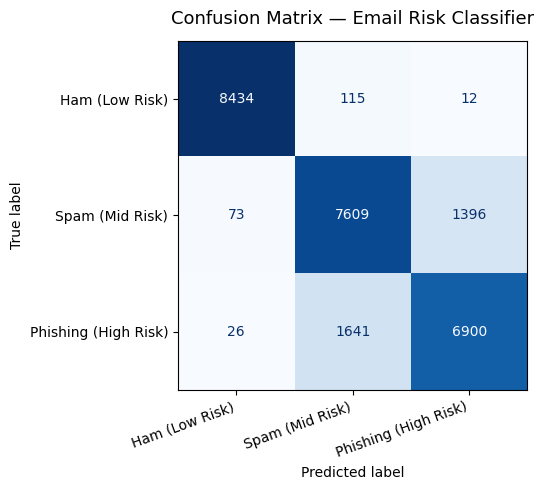

✅ Saved: confusion_matrix.png → Google Drive


In [19]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
).plot(ax=ax, cmap='Blues', colorbar=False)

ax.set_title('Confusion Matrix — Email Risk Classifier', fontsize=13, pad=12)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()

# Save to Drive
CM_PATH = '/content/drive/MyDrive/confusion_matrix.png'
plt.savefig(CM_PATH, dpi=150)
plt.show()
print(f" Saved: confusion_matrix.png → Google Drive")

In [20]:
print("=" * 60)
print("predict_proba demo — 5 random samples from the test set")
print("=" * 60)

sample_indices = np.random.choice(len(X_test), size=5, replace=False)

for i, idx in enumerate(sample_indices, 1):
    text  = X_test.iloc[idx]
    true  = y_test.iloc[idx]
    proba = y_proba[idx]
    pred  = y_pred[idx]

    print(f"\nSample {i}:")
    print(f"  Text snippet : \"{text[:70]}...\"")
    print(f"  True label   : {label_names[true]}")
    print(f"  Predicted    : {label_names[pred]}  {'✅' if pred == true else '❌'}")
    print(f"  Probabilities:")
    for class_idx, prob in enumerate(proba):
        bar = '█' * int(prob * 30)
        print(f"    {label_names[class_idx]:25s}  {prob*100:5.1f}%  {bar}")

predict_proba demo — 5 random samples from the test set

Sample 1:
  Text snippet : "hello life full luxury yet handful people afford finest product luxury..."
  True label   : Spam (Mid Risk)
  Predicted    : Spam (Mid Risk)  ✅
  Probabilities:
    Ham (Low Risk)               0.0%  
    Spam (Mid Risk)             94.0%  ████████████████████████████
    Phishing (High Risk)         5.9%  █

Sample 2:
  Text snippet : "right tool valuable resource rumor true true make lot money marketing ..."
  True label   : Phishing (High Risk)
  Predicted    : Phishing (High Risk)  ✅
  Probabilities:
    Ham (Low Risk)               0.0%  
    Spam (Mid Risk)             43.1%  ████████████
    Phishing (High Risk)        56.9%  █████████████████

Sample 3:
  Text snippet : "raj mohammed rajmohammed4444hotmailfr mr raj mohammed manager african ..."
  True label   : Phishing (High Risk)
  Predicted    : Phishing (High Risk)  ✅
  Probabilities:
    Ham (Low Risk)               0.0%  
    Spam (Mid Ri